# Advanced Crop Yield Prediction
**BTech Machine Learning Lab • Nidhish Bansal and Yash Vishnoi**

This notebook compares **Histogram Gradient Boosting, Extra Trees, and a multi-layer neural network (MLP)**. We also rerun the earlier Random Forest as a reference.

**Question:** Can these models estimate yield for later years from country, crop, year, rainfall, pesticide use, and temperature?

All these models learn from historical data. A neural network is not automatically better at predicting the future. We test that idea using later years that the models have not seen. The output is a **conditional scenario estimate**: future weather and pesticide inputs must be supplied.

Run all cells from top to bottom using the project's Python environment. The notebook uses the existing pandas, NumPy, matplotlib, and scikit-learn packages. It reads `dataset/yield_df.csv` and does not save models or change the CSV.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import (
    HistGradientBoostingRegressor, ExtraTreesRegressor, RandomForestRegressor
)
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = ["#147d92", "#d49c28", "#6a60a9", "#738579"]
# Limit native library threads to keep this small lab experiment responsive.
thread_limits = threadpool_limits(limits=2)


## 1. Understand the data
Each row records a country/crop/year observation with environmental inputs. Yield is measured in **hectograms per hectare (hg/ha)**. Divide by **10,000** to get tonnes/hectare.

| Input | Meaning |
|---|---|
| Area, Item | Country and crop |
| Year | Observation year |
| average_rain_fall_mm_per_year | Annual rainfall in mm |
| pesticides_tonnes | Pesticide-use measure in tonnes; not a field application rate |
| avg_temp | Average temperature in °C |
| hg/ha_yield | Target to predict; never an input |

These are aggregated records, not individual farm measurements. Multiple rows can share a country, crop, and year, so the number of rows is not the number of independent seasons.

In [2]:
data_path = Path("dataset/yield_df.csv")
if not data_path.exists():
    raise FileNotFoundError("Open this notebook from the project root containing dataset/.")

original_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
data = pd.read_csv(data_path)
data = data.drop(columns=[c for c in data if c.startswith("Unnamed:")])

target = "hg/ha_yield"
categories = ["Area", "Item"]
numbers = ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
features = categories + numbers

assert set(features + [target]).issubset(data.columns)
assert not data[features + [target]].isna().any().any(), "Review missing values first."
assert np.isfinite(data[numbers + [target]].to_numpy()).all()
assert (data[target] >= 0).all()

print(f"{len(data):,} rows | {data.Area.nunique()} countries | {data.Item.nunique()} crops")
print(f"Years: {data.Year.min()}–{data.Year.max()}")
print("Exact duplicate rows:", data.duplicated().sum())
print("Repeated country/crop/year keys:", data.duplicated(["Area", "Item", "Year"]).sum())
display(data.head())
display(data[numbers + [target]].describe().round(2))


28,242 rows | 101 countries | 10 crops
Years: 1990–2013
Exact duplicate rows: 2310
Repeated country/crop/year keys: 15112


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


,Year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,hg/ha_yield
count,28242.00,28242.00,28242.00,28242.00,28242.00
mean,2001.54,1149.06,37076.91,20.54,77053.33
std,7.05,709.81,59958.78,6.31,84956.61
min,1990.00,51.00,0.04,1.30,50.00
25%,1995.00,593.00,1702.00,16.70,19919.25
50%,2001.00,1083.00,17529.44,21.51,38295.00
75%,2008.00,1668.00,48687.88,26.00,104676.75
max,2013.00,3240.00,367778.00,30.65,501412.00


## 2. A quick look at yield
The distribution helps us see the scale of the target. Crop averages can differ substantially, which is one reason crop identity matters. We preserve large valid yields; an extreme value is not automatically a data error.

The overall yearly mean also depends on which countries and crops are represented. It should not be interpreted as a fixed-population global yield index.

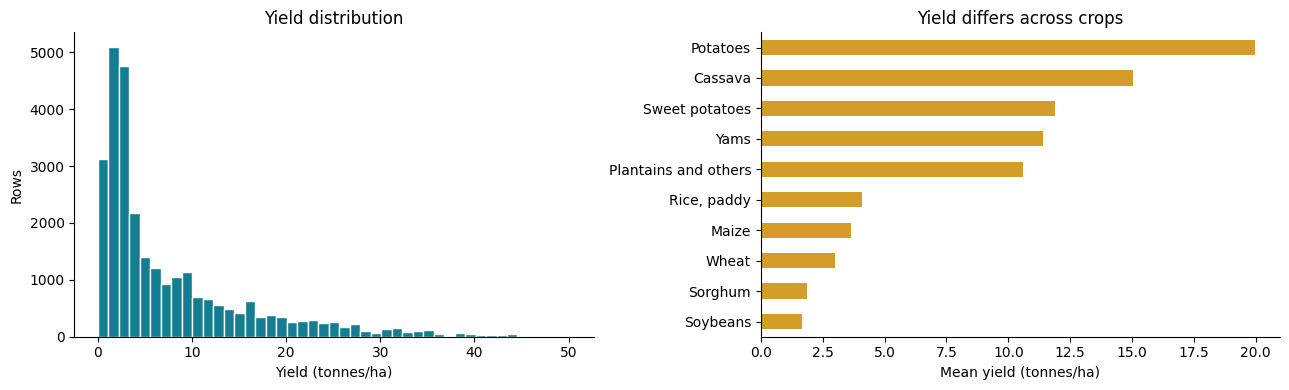

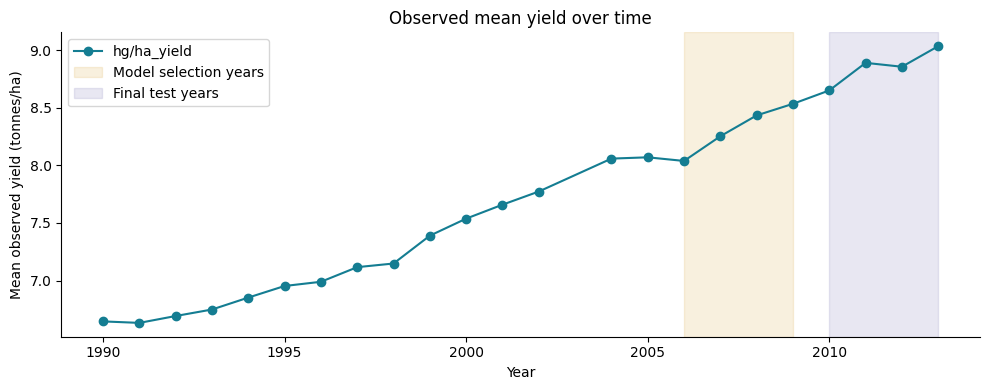

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(data[target] / 10000, bins=45, color=COLORS[0], edgecolor="white")
axes[0].set(xlabel="Yield (tonnes/ha)", ylabel="Rows", title="Yield distribution")
(data.groupby("Item")[target].mean().sort_values() / 10000).plot.barh(
    ax=axes[1], color=COLORS[1])
axes[1].set(xlabel="Mean yield (tonnes/ha)", ylabel="", title="Yield differs across crops")
plt.tight_layout()
plt.show()

(data.groupby("Year")[target].mean() / 10000).plot(marker="o", color=COLORS[0])
plt.axvspan(2006, 2009, alpha=.15, color=COLORS[1], label="Model selection years")
plt.axvspan(2010, 2013, alpha=.15, color=COLORS[2], label="Final test years")
plt.ylabel("Mean observed yield (tonnes/ha)")
plt.title("Observed mean yield over time")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Keep time moving forward
We choose the model before looking at final test errors.

| Stage | Fit on | Evaluate on | Purpose |
|---|---|---|---|
| Model selection | 1990–2005 | 2006–2009 | Select the lowest validation RMSE |
| Final evaluation | 1990–2009 | 2010–2013 | Compare later-year performance |
| Scenario prediction | 1990–2013 | Future input scenario | Use all available history |

This is one chronological validation window, not an extensive tuning study. We fix the model settings in advance. A stronger follow-up would use several expanding-year validation windows. Country/crop/year groups stay together because all rows from a year remain in one period.

The previous script selected its winner using the test scores. This notebook improves that procedure by reserving a separate earlier validation period.

In [4]:
selection_train = data.Year.between(1990, 2005)
validation = data.Year.between(2006, 2009)
full_train = data.Year.between(1990, 2009)
test = data.Year.between(2010, 2013)

X, y = data[features], data[target]
assert not (full_train & test).any()
assert X.loc[full_train, "Year"].max() < X.loc[test, "Year"].min()
assert all(mask.any() for mask in [selection_train, validation, full_train, test])

display(pd.DataFrame({
    "Period": ["Selection training", "Validation", "Final training", "Final test"],
    "Rows": [selection_train.sum(), validation.sum(), full_train.sum(), test.sum()]
}))
print("Countries only in the final test:",
      sorted(set(X.loc[test, "Area"]) - set(X.loc[full_train, "Area"])))


,Period,Rows
0,Selection training,18262
1,Validation,4971
2,Final training,23233
3,Final test,5009


Countries only in the final test: ['Sudan']


## 4. Preprocessing and model choices
**One-hot encoding** turns country and crop names into numeric indicator columns. Unseen categories are accepted, but accepting them does not establish accurate predictions for them.

**StandardScaler** puts numeric inputs on comparable scales, which helps the neural network. Tree models do not require scaling, but using the same preprocessing keeps the experiment simple. Each pipeline learns its transformations from its own training partition only. The MLP target is also standardized during fitting and converted back automatically.

| Model | How it learns | Why include it? |
|---|---|---|
| Histogram Gradient Boosting | Adds trees that correct earlier errors; groups numeric values into bins | Learns nonlinear relationships efficiently |
| Extra Trees | Averages many trees with randomized split thresholds | Another way to reduce the variability of individual trees |
| Neural Network (MLP) | Three hidden layers of 128, 64, and 32 neurons learn nonlinear combinations | Tests whether learned feature combinations improve later-year predictions |
| Random Forest reference | Averages trees trained on bootstrap samples | Checks whether extra complexity beats the earlier approach |

The MLP uses ReLU activations, Adam optimization, and early stopping. Its internal stopping subset is randomly drawn **only from the current training period**. It is an optimization aid, not our chronological validation score. Preprocessing is fitted on that whole training period, so the internal stopping score is not an independent performance estimate. Only the external validation/test periods provide that evaluation.

In [5]:
def make_pipeline(model):
    preprocessing = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
        ("numbers", StandardScaler(), numbers)
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

models = {
    "Gradient Boosting": make_pipeline(HistGradientBoostingRegressor(
        learning_rate=0.08, max_iter=250, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=42)),
    "Extra Trees": make_pipeline(ExtraTreesRegressor(
        n_estimators=250, max_features=0.8, min_samples_leaf=2,
        n_jobs=2, random_state=42)),
    "Neural Network": make_pipeline(TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(128, 64, 32), activation="relu", solver="adam",
            batch_size=256, learning_rate_init=0.001, early_stopping=True,
            validation_fraction=0.15, n_iter_no_change=20,
            max_iter=300, random_state=42),
        transformer=StandardScaler())),
    "Random Forest reference": make_pipeline(RandomForestRegressor(
        n_estimators=50, max_depth=None, min_samples_split=5,
        n_jobs=2, random_state=42))
}

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }


## 5. Choose a model using validation years
**MAE** is the average absolute error. **RMSE** penalizes large errors more strongly. Both are in hg/ha and lower is better. **R²** compares squared errors with a constant prediction of the evaluation set's mean: 1 is perfect, 0 matches that reference, and negative values are possible. R² is not percentage accuracy.

We choose the lowest validation RMSE across all four candidates, allowing the original baseline to win if appropriate. Hyperparameter settings are fixed for this experiment; we do not tune them on 2010–2013.

In [6]:
validation_rows = []
for name, template in models.items():
    print("Validating:", name, flush=True)
    model = clone(template)
    model.fit(X.loc[selection_train], y.loc[selection_train])
    predicted = model.predict(X.loc[validation])
    validation_rows.append({"Model": name, **calculate_metrics(y.loc[validation], predicted)})

validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("RMSE")
selected_name = validation_results.index[0]
display(validation_results.round(3))
print("Selected before final testing:", selected_name)


Validating: Gradient Boosting


Validating: Extra Trees


Validating: Neural Network


Validating: Random Forest reference


,MAE,RMSE,R2
Model,,,
Extra Trees,8313.425,16102.478,0.969
Random Forest reference,8589.789,16732.869,0.966
Neural Network,10600.090,18661.863,0.958
Gradient Boosting,11877.285,20919.691,0.947


Selected before final testing: Extra Trees


## 6. Final evaluation on 2010–2013
We now refit each model using 1990–2009 and evaluate all of them on exactly the same later rows. The selected model remains the validation winner even if a different model happens to rank first on this test period. Repeatedly changing settings after viewing these results would turn this test into another validation set.

In [7]:
fitted_models = {}
test_predictions = {}
test_rows = []

for name, template in models.items():
    print("Final evaluation:", name, flush=True)
    start = perf_counter()
    model = clone(template)
    model.fit(X.loc[full_train], y.loc[full_train])
    predicted = model.predict(X.loc[test])
    assert np.isfinite(predicted).all()
    metrics = calculate_metrics(y.loc[test], predicted)
    assert np.isfinite(list(metrics.values())).all()
    test_rows.append({
        "Model": name, **metrics,
        "Train R2": r2_score(y.loc[full_train], model.predict(X.loc[full_train])),
        "Fit and evaluation seconds": perf_counter() - start
    })
    fitted_models[name] = model
    test_predictions[name] = predicted

test_results = pd.DataFrame(test_rows).set_index("Model")
display(test_results.sort_values("RMSE").round(3))
reference_rmse = test_results.loc["Random Forest reference", "RMSE"]
selected_rmse = test_results.loc[selected_name, "RMSE"]
change = 100 * (reference_rmse - selected_rmse) / reference_rmse
print(f"Validation-selected model: {selected_name}")
print(f"Test RMSE change relative to Random Forest: {change:+.2f}% (positive = lower error)")
print("This single historical test period does not establish performance in all future years.")


Final evaluation: Gradient Boosting


Final evaluation: Extra Trees


Final evaluation: Neural Network


Final evaluation: Random Forest reference


,MAE,RMSE,R2,Train R2,Fit and evaluation seconds
Model,,,,,
Neural Network,11221.705,19397.042,0.959,0.991,13.938
Extra Trees,10152.975,19942.622,0.956,0.997,42.390
Random Forest reference,10442.003,20533.341,0.954,0.997,5.600
Gradient Boosting,13459.170,23347.448,0.940,0.977,6.555


Validation-selected model: Extra Trees
Test RMSE change relative to Random Forest: +2.88% (positive = lower error)
This single historical test period does not establish performance in all future years.


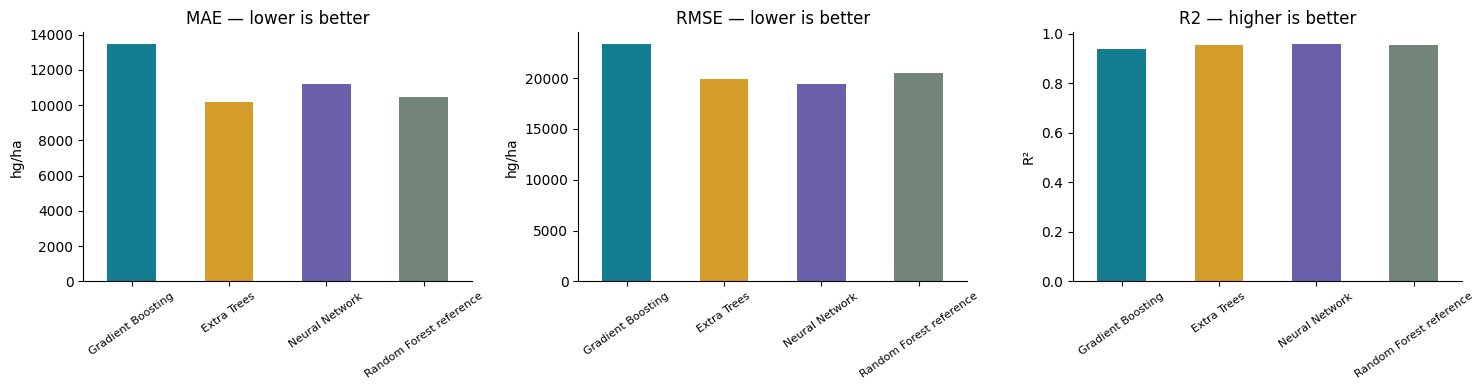

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    test_results[metric].plot.bar(ax=ax, color=COLORS, rot=35)
    ax.set_title(metric + (" — lower is better" if metric != "R2" else " — higher is better"))
    ax.set_xlabel("")
    ax.set_ylabel("hg/ha" if metric != "R2" else "R²")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()


**How to discuss the table:** Prefer test errors to training fit. A very high training R² with a lower test R² suggests weaker generalization. MAE and RMSE may favor different models because RMSE gives more weight to large misses. Any gain over the reference is evidence for this dataset and time period, not proof that neural networks always outperform forests.

## 7. Actual values, predictions, and residuals
Points close to the diagonal indicate accurate predictions. A residual is **actual minus predicted yield**: positive means underprediction and negative means overprediction. A good residual plot is centered near zero without a strong pattern. These plots show every final-test observation.

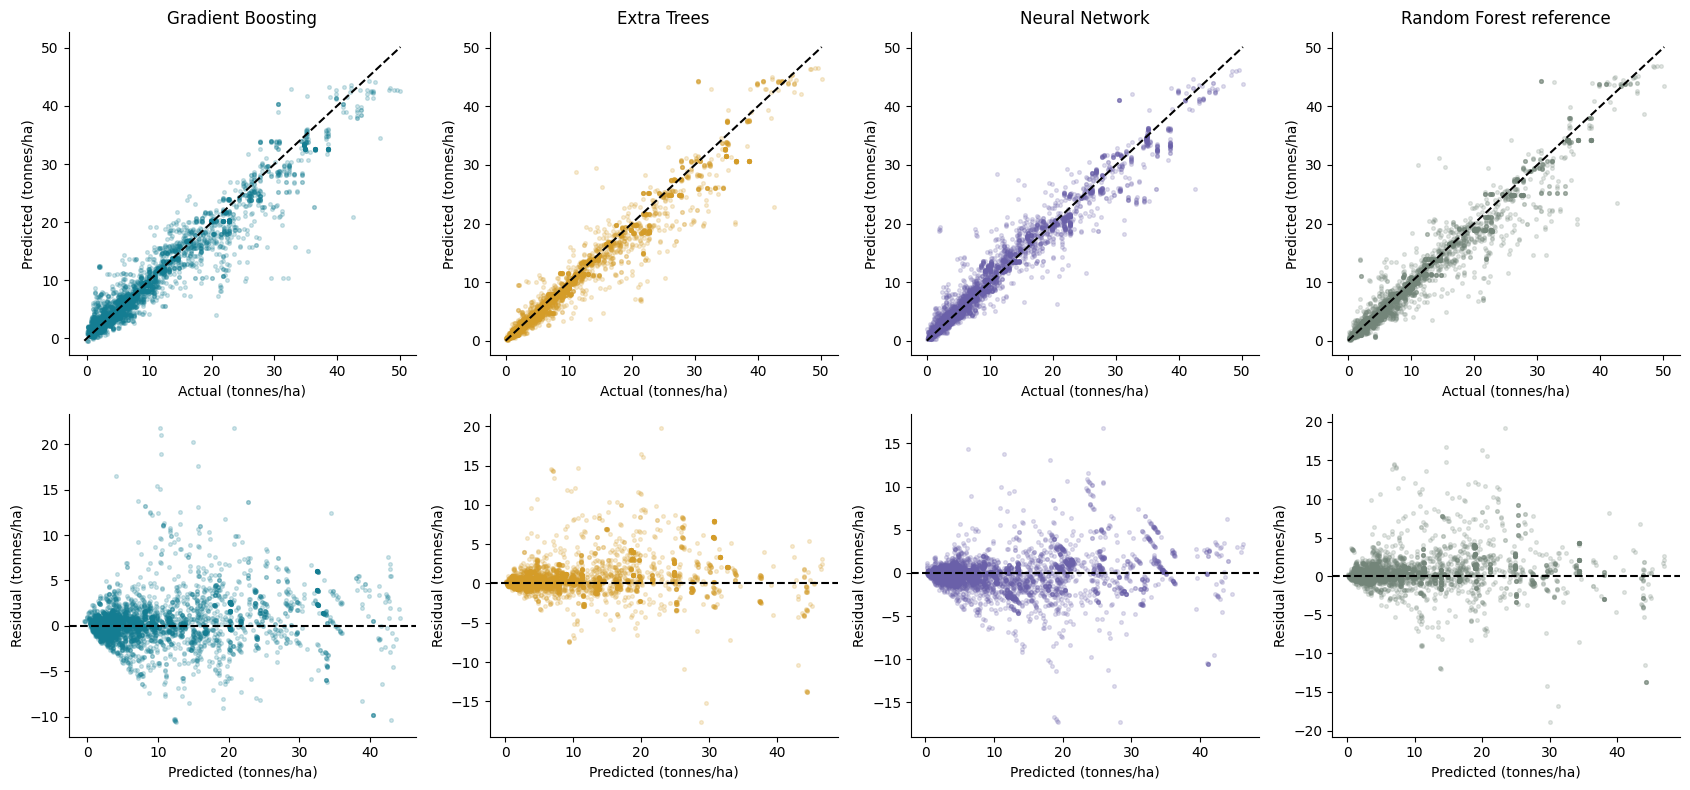

In [9]:
actual = y.loc[test].to_numpy()
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for column, (name, predicted) in enumerate(test_predictions.items()):
    upper = max(actual.max(), predicted.max()) / 10000
    lower = min(0, predicted.min() / 10000)
    axes[0, column].scatter(actual / 10000, predicted / 10000,
                            s=7, alpha=.2, color=COLORS[column])
    axes[0, column].plot([lower, upper], [lower, upper], "--", color="black")
    axes[0, column].set(title=name, xlabel="Actual (tonnes/ha)", ylabel="Predicted (tonnes/ha)")
    axes[1, column].scatter(predicted / 10000, (actual - predicted) / 10000,
                            s=7, alpha=.2, color=COLORS[column])
    axes[1, column].axhline(0, color="black", linestyle="--")
    axes[1, column].set(xlabel="Predicted (tonnes/ha)", ylabel="Residual (tonnes/ha)")
plt.tight_layout()
plt.show()


## 8. Does performance change across years and crops?
An overall score can hide weak performance for a particular year or crop. The crop table reports the selected model's errors and sample counts. High-yield crops naturally tend to have larger absolute errors, so compare these results with the yield scales as well.

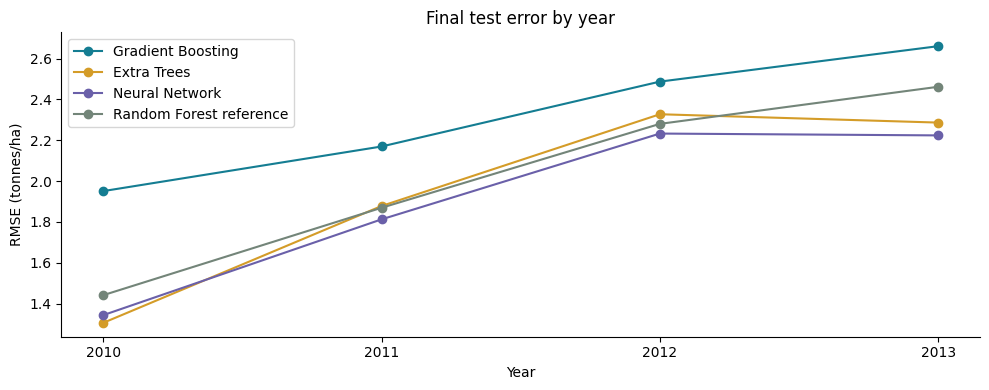

,Rows,MAE,RMSE
Item,,,
Plantains and others,100,17343.99,34277.34
Cassava,356,22767.63,33306.40
Sweet potatoes,508,18699.36,31527.78
Potatoes,760,21485.05,31410.64
Yams,152,10662.37,20373.80
Sorghum,550,4065.62,9288.70
Maize,732,6045.11,9255.08
"Rice, paddy",596,5009.72,7073.82
Wheat,680,3717.02,4795.39


In [10]:
year_errors = {}
for name, predicted in test_predictions.items():
    check = pd.DataFrame({"Year": X.loc[test, "Year"].to_numpy(),
                          "Squared error": (actual - predicted) ** 2})
    year_errors[name] = np.sqrt(check.groupby("Year")["Squared error"].mean()) / 10000

pd.DataFrame(year_errors).plot(marker="o", color=COLORS)
plt.ylabel("RMSE (tonnes/ha)")
plt.title("Final test error by year")
plt.xticks([2010, 2011, 2012, 2013])
plt.tight_layout()
plt.show()

crop_check = X.loc[test, ["Item"]].copy()
crop_check["Absolute error"] = np.abs(actual - test_predictions[selected_name])
crop_check["Squared error"] = (actual - test_predictions[selected_name]) ** 2
crop_summary = crop_check.groupby("Item").agg(
    Rows=("Absolute error", "size"), MAE=("Absolute error", "mean"),
    MSE=("Squared error", "mean"))
crop_summary["RMSE"] = np.sqrt(crop_summary.pop("MSE"))
display(crop_summary.sort_values("RMSE", ascending=False).round(2))


## 9. What did the neural network learn during training?
The loss curve tracks its training objective in standardized target units. It is not yield error in hg/ha. The second curve is the internal early-stopping R². These curves explain optimization; the chronological test scores above explain generalization.

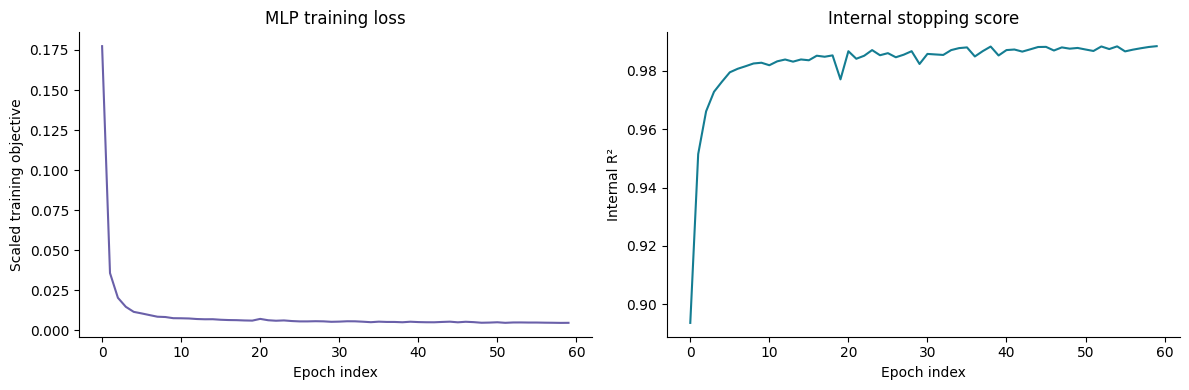

Epochs used: 60


In [11]:
network = fitted_models["Neural Network"].named_steps["model"].regressor_
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(network.loss_curve_, color=COLORS[2])
axes[0].set(title="MLP training loss", xlabel="Epoch index", ylabel="Scaled training objective")
axes[1].plot(network.validation_scores_, color=COLORS[0])
axes[1].set(title="Internal stopping score", xlabel="Epoch index", ylabel="Internal R²")
plt.tight_layout()
plt.show()
print("Epochs used:", network.n_iter_)


## 10. Which input features does the selected model rely on?
Permutation importance shuffles one input column and measures the increase in prediction error. A larger increase suggests the model relies more on that input. This is an explanation of model behavior, **not proof of cause and effect**. Correlated features and unrealistic shuffled combinations can affect the result.

We use a reproducible sample of up to 1,200 test rows and three shuffles per feature. This is a post-evaluation explanation; it does not change the selected model.

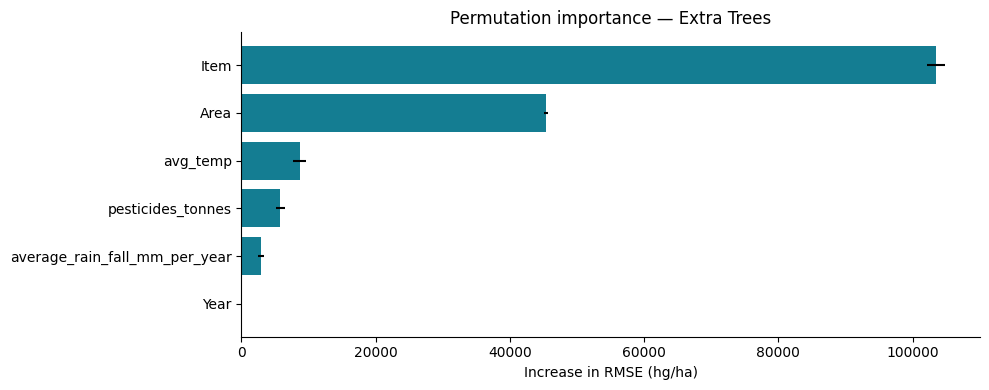

,Feature,RMSE increase,Shuffle standard deviation
2,Year,0.00,0.00
3,average_rain_fall_mm_per_year,2878.90,420.30
4,pesticides_tonnes,5808.49,613.89
5,avg_temp,8675.80,1005.73
0,Area,45378.04,321.76
1,Item,103462.31,1334.44


In [12]:
sample_X = X.loc[test].sample(n=min(1200, test.sum()), random_state=42)
sample_y = y.loc[sample_X.index]
importance = permutation_importance(
    fitted_models[selected_name], sample_X, sample_y,
    scoring="neg_root_mean_squared_error", n_repeats=3, random_state=42, n_jobs=1)
importance_table = pd.DataFrame({
    "Feature": features, "RMSE increase": importance.importances_mean,
    "Shuffle standard deviation": importance.importances_std
}).sort_values("RMSE increase")
plt.barh(importance_table["Feature"], importance_table["RMSE increase"],
         xerr=importance_table["Shuffle standard deviation"], color=COLORS[0])
plt.xlabel("Increase in RMSE (hg/ha)")
plt.title(f"Permutation importance — {selected_name}")
plt.tight_layout()
plt.show()
display(importance_table.round(2))


## 11. Predict yield for a future scenario
After completing evaluation, we refit the **validation-selected model** on all available years. Edit the dictionary below to explore another scenario. The default year, 2014, is future relative to this dataset, which ends in 2013.

Rainfall, temperature, and pesticide use must be supplied as assumptions or obtained from independent forecasts. Having future-year inputs does not guarantee that the learned relationships will remain valid. Tree models generally cannot extend a learned time trend beyond their splits; an MLP can extrapolate, but its extrapolation can also be unreliable.

A distant year such as 2026 is far beyond this dataset's coverage. Recent observations and new validation would be needed to support reliable current forecasts.

In [13]:
future_scenario = {
    "Area": "India",
    "Item": "Wheat",
    "Year": 2014,
    "average_rain_fall_mm_per_year": 1083.0,
    "pesticides_tonnes": 45620.0,
    "avg_temp": 27.0
}

assert future_scenario["Year"] > data.Year.max(), "Use a year after the observed history."
assert np.isfinite([future_scenario[c] for c in numbers]).all()
assert future_scenario["average_rain_fall_mm_per_year"] >= 0
assert future_scenario["pesticides_tonnes"] >= 0

for column in categories:
    if future_scenario[column] not in set(data[column]):
        print(f"Caution: unseen {column}; this category has no learned category-specific effect.")
for column in numbers[1:]:
    if not data[column].min() <= future_scenario[column] <= data[column].max():
        print(f"Caution: {column} is outside the observed range.")

final_model = clone(models[selected_name])
final_model.fit(X, y)
future_X = pd.DataFrame([future_scenario], columns=features)
future_yield = float(final_model.predict(future_X)[0])
assert np.isfinite(future_yield)
display(future_X)
print("Model:", selected_name)
print(f"Estimated yield: {future_yield:,.0f} hg/ha = {future_yield / 10000:.2f} tonnes/ha")
if future_yield < 0:
    print("The negative output is physically invalid: do not use this scenario estimate.")
print("No prediction interval is estimated in this experiment.")


,Area,Item,Year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,India,Wheat,2014,1083.0,45620.0,27.0


Model: Extra Trees
Estimated yield: 31,510 hg/ha = 3.15 tonnes/ha
No prediction interval is estimated in this experiment.


## 12. A small scenario experiment
Here we vary rainfall while keeping every other input fixed. This shows how the fitted model responds to one changed input. The curve is not a causal estimate of what irrigation would do and does not establish that one rainfall level is optimal.

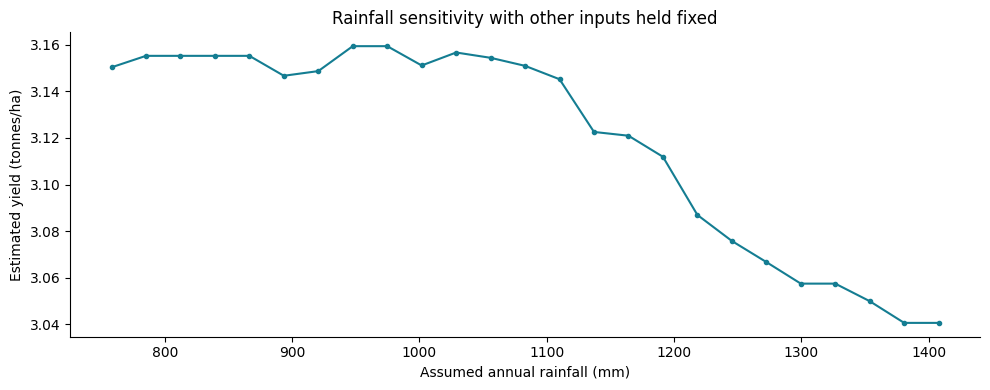

In [14]:
rainfall_scenarios = pd.concat([future_X] * 25, ignore_index=True)
rainfall_scenarios["average_rain_fall_mm_per_year"] = np.linspace(
    future_scenario["average_rain_fall_mm_per_year"] * .7,
    future_scenario["average_rain_fall_mm_per_year"] * 1.3, 25)
scenario_predictions = final_model.predict(rainfall_scenarios) / 10000
plt.plot(rainfall_scenarios["average_rain_fall_mm_per_year"],
         scenario_predictions, marker=".", color=COLORS[0])
plt.xlabel("Assumed annual rainfall (mm)")
plt.ylabel("Estimated yield (tonnes/ha)")
plt.title("Rainfall sensitivity with other inputs held fixed")
plt.tight_layout()
plt.show()


## 13. Checks and conclusions for the viva
- **Why advanced models?** To compare different ways of learning nonlinear patterns; complexity alone does not guarantee an improvement.
- **Why this split?** It imitates using earlier observations to estimate later yields. Random splitting can place closely related years and records on both sides.
- **Which model is best?** Report the validation-selected model and its measured test MAE/RMSE/R². The lowest test error is descriptive and does not replace the selection rule.
- **Is this a time-series neural network?** No. The MLP processes tabular rows and year as a feature. It has no sequence memory or lagged-yield inputs.
- **Why no LSTM?** A sequence model requires carefully constructed country/crop sequences. Multiple records per year and only 24 calendar years need attention before doing that.
- **Is R² accuracy?** No. R² measures squared-error performance relative to a mean reference.
- **Can this advise individual farmers?** The country-level data lacks soil, irrigation, crop variety, field management, and detailed seasonal weather.
- **Can it predict unknown weather?** No. Its yield output is conditional on the supplied weather and pesticide scenario.

**Limitations:** old data, repeated country/crop/year keys, unequal crop/country coverage, one validation period, and no uncertainty intervals. High aggregate R² may partly reflect differences between crop yield scales. The Random Forest reference settings were inherited from earlier project work, so this is a practical comparison rather than a completely fresh benchmark.

**Next experiments:** audit the joins behind repeated records; obtain recent and regional data; evaluate several rolling time windows; add soil/irrigation/seasonal weather and carefully shifted lag features; compare with a last-observed-yield baseline; and estimate prediction intervals. Only values available at prediction time should become features.

In [15]:
# A new country must not crash the encoding or prediction.
unseen_example = X.loc[test].iloc[[0]].copy()
unseen_example["Area"] = "__unseen_country_for_check__"
for name, model in fitted_models.items():
    assert np.isfinite(model.predict(unseen_example)).all(), name

assert hashlib.sha256(data_path.read_bytes()).hexdigest() == original_hash
assert target not in features
assert len(test_predictions) == 4
assert np.isfinite(test_results[["MAE", "RMSE", "R2"]].to_numpy()).all()

print("Checks passed: finite metrics, unseen-category handling, and unchanged source CSV.")
print("Selected model:", selected_name)
print(f"Selected model test MAE: {test_results.loc[selected_name, 'MAE']:,.2f} hg/ha")
print(f"Selected model test RMSE: {selected_rmse:,.2f} hg/ha")
print(f"Selected model test R²: {test_results.loc[selected_name, 'R2']:.4f}")


Checks passed: finite metrics, unseen-category handling, and unchanged source CSV.
Selected model: Extra Trees
Selected model test MAE: 10,152.98 hg/ha
Selected model test RMSE: 19,942.62 hg/ha
Selected model test R²: 0.9564
